## Linear Function Approximator

In [2]:
import numpy as np
import matplotlib.pyplot as plt


class LinearFunctionApproximator:
    def __init__(self, num_features):
        self.theta = np.random.rand(num_features)

    def predict(self, phi_s):
      return np.dot(self.theta, phi_s)

    def update(self, phi_s, target):
        prediction = self.predict(phi_s)
        error = target - prediction
        self.theta += 0.1 * error * phi_s


In [ ]:
num_features = 2
approximator = LinearFunctionApproximator(num_features)
num_episodes = 10

for episode in range(num_episodes):
    phi_s = np.random.rand(num_features)
    target_value = 10 * phi_s[0] + 5 * phi_s[1]
    approximator.update(phi_s, target_value)

test = np.array([0.8, 0.2])
predicted_value = approximator.predict(test)
print(f"Predicted Value for phi_s {test}: {predicted_value}")

In [ ]:
approximator.theta

## Sin

In [ ]:
num_terms = 1
approximator = LinearFunctionApproximator(num_terms)
num_episodes = 1000

for episode in range(num_episodes):
    x = np.random.uniform(-np.pi, np.pi)
    features = np.array([x**i / np.math.factorial(i) for i in range(1, 2 * num_terms, 2)])
    target_value = np.sin(x)
    approximator.update(features, target_value)


test_x_values = np.linspace(-np.pi, np.pi, 100)
predicted_values = [approximator.predict([x**i / np.math.factorial(i) for i in range(1, 2 * num_terms, 2)]) for x in test_x_values]

plt.plot(test_x_values, np.sin(test_x_values), label='True sin(x)')
plt.plot(test_x_values, predicted_values, label='Approximation')
plt.legend()
plt.title('Linear Approximation of sin(x)')
plt.xlabel('x')
plt.ylabel('sin(x)')
plt.show()

# RBF Network

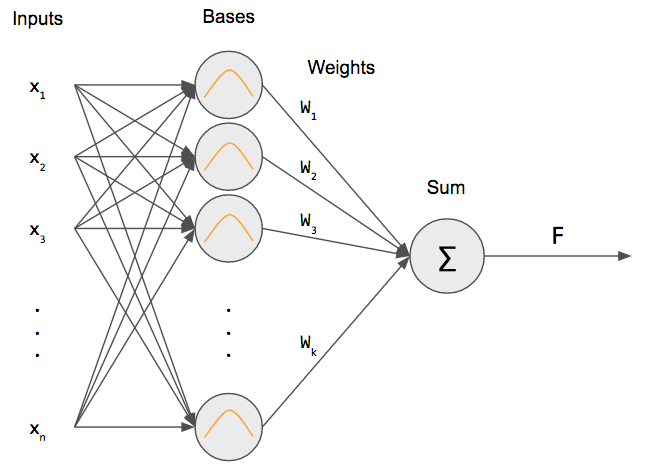

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import random
from sklearn.metrics import mean_squared_error
from scipy.spatial.distance import cdist

class RBFNetwork:
    def __init__(self, num_centers, sigma):
        # Hyperparameters -> about 8 solution!
        self.num_centers = num_centers  # Number of RBF centers
        self.sigma = sigma              # Spread parameter for RBF  -> 1
        self.centers = None             # Centers of RBFs
        self.weights = None             # Weights of the network
        self.bias = None                # Bias term

    def _rbf(self, x, c):
        """
        Gaussian RBF function.
        """
        return np.exp(-self.sigma * np.linalg.norm(x - c, axis=1)**2)

    def fit(self, X, y):
        """
        Train the RBF network.
        """
        # method1: each data = center
        # self.centers = X

        # method 2: choose random from X as center
        # self.centers = random.choices(X, k = 10)

        # method 3:Determine RBF centers using K-Means
        # kmeans = KMeans(n_clusters  = self.num_centers, random_state = 100)
        # kmeans.fit(X)
        # self.centers = kmeans.cluster_centers_

        # method 3.1: Determine RBF centers using K-Means with specific sigma based on distance (cdist (norm-2))
        kmeans = KMeans(n_clusters  = self.num_centers, random_state = 100)
        kmeans.fit(X)
        self.centers = kmeans.cluster_centers_
        dmax = np.max(cdist(self.centers, self.centers, 'euclidean'))
        self.sigma = dmax / np.sqrt(2 * len(self.centers))


        # Step 2: Compute RBF activations
        G = np.array([self._rbf(x, self.centers) for x in X])

        # Step 3: Solve for weights using least squares
        self.weights, _, _, _ = np.linalg.lstsq(G, y, rcond=None)
        self.bias = np.mean(y)  # Bias initialization

    def predict(self, X):
        """
        Predict output for given inputs.
        """
        G = np.array([self._rbf(x, self.centers) for x in X])
        return G @ self.weights + self.bias

# Generate synthetic data
np.random.seed(42)
X = np.random.uniform(0, 1, (100, 1))  # Inputs
y = np.sin(2 * np.pi * X).flatten() + 0.1 * np.random.randn(100)  # Noisy outputs

# Train-test split
train_X, test_X = X[:80], X[80:]
train_y, test_y = y[:80], y[80:]

# Create and train the RBF network
rbf_net = RBFNetwork(num_centers=10, sigma=1)
rbf_net.fit(train_X, train_y)

# Make predictions
predictions = rbf_net.predict(test_X)
print ("MSE error:",mean_squared_error(test_y, predictions))
# Plot the results
plt.figure(figsize=(10, 6))
plt.scatter(train_X, train_y, label="Training Data", color="blue", alpha=0.6)
plt.scatter(test_X, test_y, label="Test Data", color="green", alpha=0.6)
plt.plot(np.sort(test_X, axis=0), predictions[np.argsort(test_X, axis=0)], label="RBF Approximation", color="red")
plt.legend()
plt.title("RBF Network Function Approximation")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.show()


## Policy Gradient in Reinforcement Learning

First, please install the required packages and import these modules.

In [7]:
%%capture
!pip install python-opengl
!pip install ffmpeg
!pip install xvfb
!pip install pyvirtualdisplay
!pip install pyglet==1.5.1
!pip install imageio-ffmpeg
!pip install pyyaml==6.0
!pip install git+https://github.com/ntasfi/PyGame-Learning-Environment.git
!pip install git+https://github.com/simoninithomas/gym-games


In [8]:
import numpy as np

from collections import deque

import matplotlib.pyplot as plt
%matplotlib inline

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

# Gym
import gym
import gym_pygame

import imageio

In policy gradient, the action $a$ is picked up by the distribution $P$ which depends on policy $\pi$.<br>
To say more clearly, the distibution of action is $ P(a | \pi_\theta (s)) $, where $ \pi_\theta (s) $ is policy and $\theta$ is parameters for this policy. When the current state $s$ is given, the distribution of action $a$ is determined by this policy.

In this CartPole example, we assume that $P(\cdot)$ is a categorical distribution (because action space is discrete) and $\pi_\theta (s)$ is the following fully-connected network (fcnet).<br>
In this example, the output of this policy $\pi_\theta (s)$ will be logits value, which determines categorical distribution $P(\cdot)$.

![](https://www.researchgate.net/publication/360910430/figure/fig1/AS:11431281080452861@1661307888574/Deep-reinforcement-learning-scheme-A-deep-neural-network-learns-the-policy_W640.jpg)

> Note : When logits $v_0, v_1$ are given, the probabilities are $\frac{e^{v_0}}{e^{v_0}+e^{v_1}}, \frac{e^{v_1}}{e^{v_0}+e^{v_1}}$ respectively.

First, we implement $\pi_\theta (s)$ (fully-connected network) using PyTorch as follows.

### impelement network

In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
class Policy(nn.Module):
    def __init__(self, s_size, a_size, h_size):
        super(Policy, self).__init__()
        self.fc1 = nn.Linear(s_size, h_size)
        self.fc2 = nn.Linear(h_size, a_size)
    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        out = F.softmax(x, dim=1)

        return out

    def act(self, state):
        state = torch.from_numpy(state).float().unsqueeze(0).to(device)
        # probs = self.forward(...).cpu()
        probs = self.forward(state).cpu()
        # m = Categorical(...)
        m = Categorical(probs)

        action = m.sample()
        return action.item(), m.log_prob(action)

### define environment
https://gymnasium.farama.org/environments/classic_control/

In [ ]:
env_id = "CartPole-v1"
# Create the env
env = gym.make(env_id)

# Create the evaluation env
eval_env = gym.make(env_id)

# Get the state space and action space
s_size = env.observation_space.shape[0]
a_size = env.action_space.n

In [ ]:
print("_____OBSERVATION SPACE_____ \n")
print("The State Space is: ", s_size)
print("Sample observation", env.observation_space.sample()) # Get a random observation

In [ ]:
print("\n _____ACTION SPACE_____ \n")
print("The Action Space is: ", a_size)
print("Action Space Sample", env.action_space.sample()) # Take a random action

### Let's build the Reinforce Training Algorithm
This is the Reinforce algorithm pseudocode:

<img src="https://huggingface.co/datasets/huggingface-deep-rl-course/course-images/resolve/main/en/unit6/pg_pseudocode.png" alt="Policy gradient pseudocode"/>

In [13]:
def reinforce(policy, optimizer, n_training_episodes, max_t, gamma, print_every):
    # Help us to calculate the score during the training
    scores_deque = deque(maxlen=100)
    scores = []
    # Line 3 of pseudocode
    for i_episode in range(1, n_training_episodes+1):
        saved_log_probs = []
        rewards = []
        state = env.reset()

        # Line 4 of pseudocode
        for t in range(max_t):
          # start code
          action , log_prob = policy.act(state)
          saved_log_probs.append(log_prob)
          state, reward, finish_episode, _ = env.step(action)
          rewards.append(reward)
          if finish_episode:
            break
          # finish the code

        scores_deque.append(sum(rewards))
        scores.append(sum(rewards))

        # Line 6 of pseudocode: calculate the return
        returns = deque(maxlen=max_t)
        n_steps = len(rewards)

        for t in range(n_steps)[::-1]:
            disc_return_t = (returns[0] if len(returns)>0 else 0)
            returns.appendleft( gamma*disc_return_t + rewards[t]   )

        ## standardization of the returns is employed to make training more stable
        eps = np.finfo(np.float32).eps.item()
        ## eps is the smallest representable float, which is
        # added to the standard deviation of the returns to avoid numerical instabilities
        returns = torch.tensor(returns)
        returns = (returns - returns.mean()) / (returns.std() + eps)

        # Line 7:
        policy_loss = []
        for log_prob, disc_return in zip(saved_log_probs, returns):
        # start the code:
         policy_loss.append(-log_prob * disc_return)



        # finish the code

        policy_loss = torch.cat(policy_loss).sum()

        # Line 8: PyTorch prefers gradient descent
        optimizer.zero_grad()
        policy_loss.backward()
        optimizer.step()

        if i_episode % print_every == 0:
            print('Episode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(scores_deque)))

    return scores

#### Define parameters

In [14]:
cartpole_hyperparameters = {
    "h_size": 16,
    "n_training_episodes": 500,
    "n_evaluation_episodes": 10,
    "max_t": 1000,
    "gamma": 1.0,
    "lr": 5e-3,
    "env_id": env_id,
    "state_space": s_size,
    "action_space": a_size,
}

### Start!

In [15]:
# Create policy and place it to the device
cartpole_policy = Policy(cartpole_hyperparameters["state_space"], cartpole_hyperparameters["action_space"], cartpole_hyperparameters["h_size"]).to(device)
cartpole_optimizer = optim.Adam(cartpole_policy.parameters(), lr=cartpole_hyperparameters["lr"])

In [ ]:
scores = reinforce(cartpole_policy,
                   cartpole_optimizer,
                   cartpole_hyperparameters["n_training_episodes"],
                   cartpole_hyperparameters["max_t"],
                   cartpole_hyperparameters["gamma"],
                   100)

In [ ]:
import matplotlib.pyplot as plt
# Generate recent 50 interval average
average_reward = []
for idx in range(len(scores)):
    avg_list = np.empty(shape=(1,), dtype=int)
    if idx < 50:
        avg_list = scores[:idx+1]
    else:
        avg_list = scores[idx-49:idx+1]
    average_reward.append(np.average(avg_list))
# Plot
plt.plot(scores)
plt.plot(average_reward)

In [18]:
def evaluate_agent(env, max_steps, n_eval_episodes, policy):
  """
  Evaluate the agent for ``n_eval_episodes`` episodes and returns average reward and std of reward.
  :param env: The evaluation environment
  :param n_eval_episodes: Number of episode to evaluate the agent
  :param policy: The Reinforce agent
  """
  episode_rewards = []
  for episode in range(n_eval_episodes):
    state = env.reset()
    step = 0
    done = False
    total_rewards_ep = 0

    for step in range(max_steps):
      action, _ = policy.act(state)
      new_state, reward, done, info = env.step(action)
      total_rewards_ep += reward

      if done:
        break
      state = new_state
    episode_rewards.append(total_rewards_ep)
  mean_reward = np.mean(episode_rewards)
  std_reward = np.std(episode_rewards)

  return mean_reward, std_reward

In [ ]:
evaluate_agent(eval_env,
               cartpole_hyperparameters["max_t"],
               cartpole_hyperparameters["n_evaluation_episodes"],
               cartpole_policy)

In [20]:
def record_video(env, policy, out_directory, fps=30):
  """
  Generate a replay video of the agent
  :param env
  :param Qtable: Qtable of our agent
  :param out_directory
  :param fps: how many frame per seconds (with taxi-v3 and frozenlake-v1 we use 1)
  """
  images = []
  done = False
  state = env.reset()
  img = env.render(mode='rgb_array')
  images.append(img)
  while not done:
    # Take the action (index) that have the maximum expected future reward given that state
    action, _ = policy.act(state)
    state, reward, done, info = env.step(action) # We directly put next_state = state for recording logic
    img = env.render(mode='rgb_array')
    images.append(img)
  imageio.mimsave(out_directory + '.mp4', [np.array(img) for i, img in enumerate(images)], fps=fps)

In [ ]:
video_path = 'ty1'
record_video(env, cartpole_policy, video_path, 30)
from IPython.display import Video
Video('/content/'+video_path +'.mp4', embed=True)

## Deep Sarsa

* use the link which is mantion below and run Deep sarsa algos for lunar lander

[link text](https://github.com/JohDonald/Deep-Q-Learning-Deep-SARSA-LunarLander-v2/blob/main/DSN_and_DQN_LunarLander.ipynb)

[link text](https://github.com/rlcode/reinforcement-learning/tree/master/1-grid-world/6-deep-sarsa)
* compare the RBF network and n layar fully connceted network



In [ ]:
!pip install gym
!pip install -U kaleido
!pip install swig
!pip install gym[all]

In [23]:
import numpy as np
import gym
from IPython.display import clear_output, display
import torch
import torch.nn as nn
import torch.nn.functional as F
import random
import copy
import time
import matplotlib.pyplot as plt

In [ ]:
env = gym.make('LunarLander-v2')